# 02 - Exploratory Data Analysis (EDA)

**Goal:** understand *who churns and how they differ from customers who stay* - and be honest about how much of that can be trusted.

**Rules we follow**
1. EDA uses only the **development set** (80% of customers). The held-out test set is not looked at, so that nothing we learn here "leaks" into modelling decisions.
2. We state what the data *shows* before saying why it *might* matter. Associations are not causes.
3. With ~5,600 customers almost any difference is "statistically significant", so we always report **effect sizes** next to p-values.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets notebooks import the src/ package

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Save the current figure into reports/figures (used by README and dashboard)."""
    plt.savefig(config.FIGURES_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
from scipy import stats
from src.data_preprocessing import load_split
df = load_split("train")
NUM = config.NUMERIC_FEATURES
CAT = config.CATEGORICAL_FEATURES
print(df.shape, f"| churn rate = {df.Churn.mean():.2%}")

def wilson_ci(k, n, z=1.96):
    """Wilson score interval for a proportion (better than the naive +/- z*sqrt(p(1-p)/n) for small n or extreme p)."""
    p = k / n; denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def churn_rate_by(data, col, order=None):
    g = data.groupby(col, observed=True)["Churn"].agg(n="size", churned="sum").reset_index()
    g["churn_rate"] = g["churned"] / g["n"]
    g[["ci_low", "ci_high"]] = [wilson_ci(k, n) for k, n in zip(g["churned"], g["n"])]
    if order is not None:
        g[col] = pd.Categorical(g[col], order, ordered=True); g = g.sort_values(col)
    return g

def plot_rate(data, col, ax, order=None, title=None):
    g = churn_rate_by(data, col, order)
    x = np.arange(len(g)); rate = g.churn_rate.to_numpy()
    ax.bar(x, rate, color="#3b6ea5", alpha=0.85)
    ax.errorbar(x, rate, yerr=[rate - g.ci_low.to_numpy(), g.ci_high.to_numpy() - rate], fmt="none", c="k", capsize=3, lw=1)
    ax.axhline(data.Churn.mean(), c="C3", ls="--", lw=1, label="overall")
    ax.set_xticks(x); ax.set_xticklabels([f"{v}\n(n={n})" for v, n in zip(g[col], g.n)], fontsize=8)
    ax.set(ylabel="Churn rate", title=title or f"Churn rate by {col}", ylim=(0, max(0.62, g.ci_high.max() + 0.03)))
    return g

(5634, 21) | churn rate = 26.54%


## A. Dataset overview

,count,mean,std,min,25%,50%,75%,max
tenure,5634.0,32.49,24.57,0.0,9.00,29.00,55.00,72.00
MonthlyCharges,5634.0,64.93,30.14,18.4,35.66,70.50,90.00,118.75
TotalCharges,5634.0,2299.33,2279.20,0.0,402.98,1394.92,3835.82,8684.80


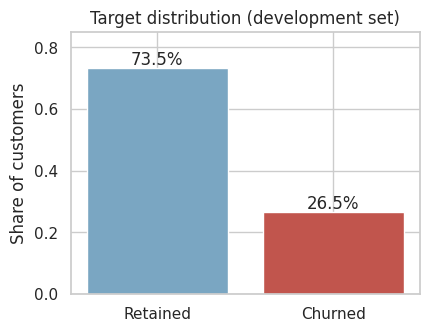

In [3]:
display(df[NUM].describe().T.round(2))
fig, ax = plt.subplots(figsize=(4.5, 3.4))
vc = df.Churn.value_counts(normalize=True).sort_index()
ax.bar(["Retained", "Churned"], vc.values, color=["#7aa6c2", "#c1554d"])
for i, v in enumerate(vc.values): ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
ax.set(ylabel="Share of customers", title="Target distribution (development set)", ylim=(0, 0.85)); savefig("eda_target_distribution.png")

## B. Univariate analysis - what does each variable look like on its own?
*Why:* detects skew, outliers, rare categories and impossible values before they distort a model. Skewed money variables, for example, matter for linear models but not for trees.

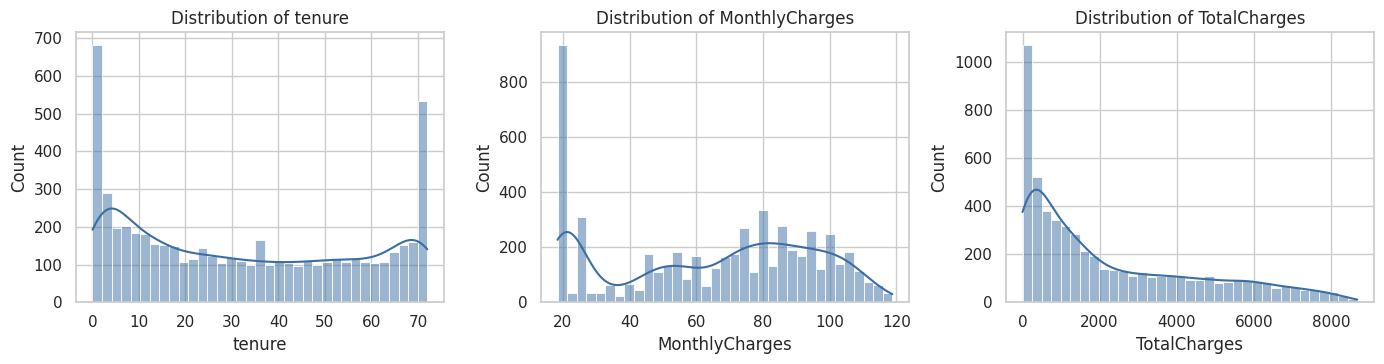

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, NUM):
    sns.histplot(df[col], bins=35, kde=True, ax=ax, color="#3b6ea5"); ax.set_title(f"Distribution of {col}")
plt.tight_layout(); savefig("eda_numeric_distributions.png")

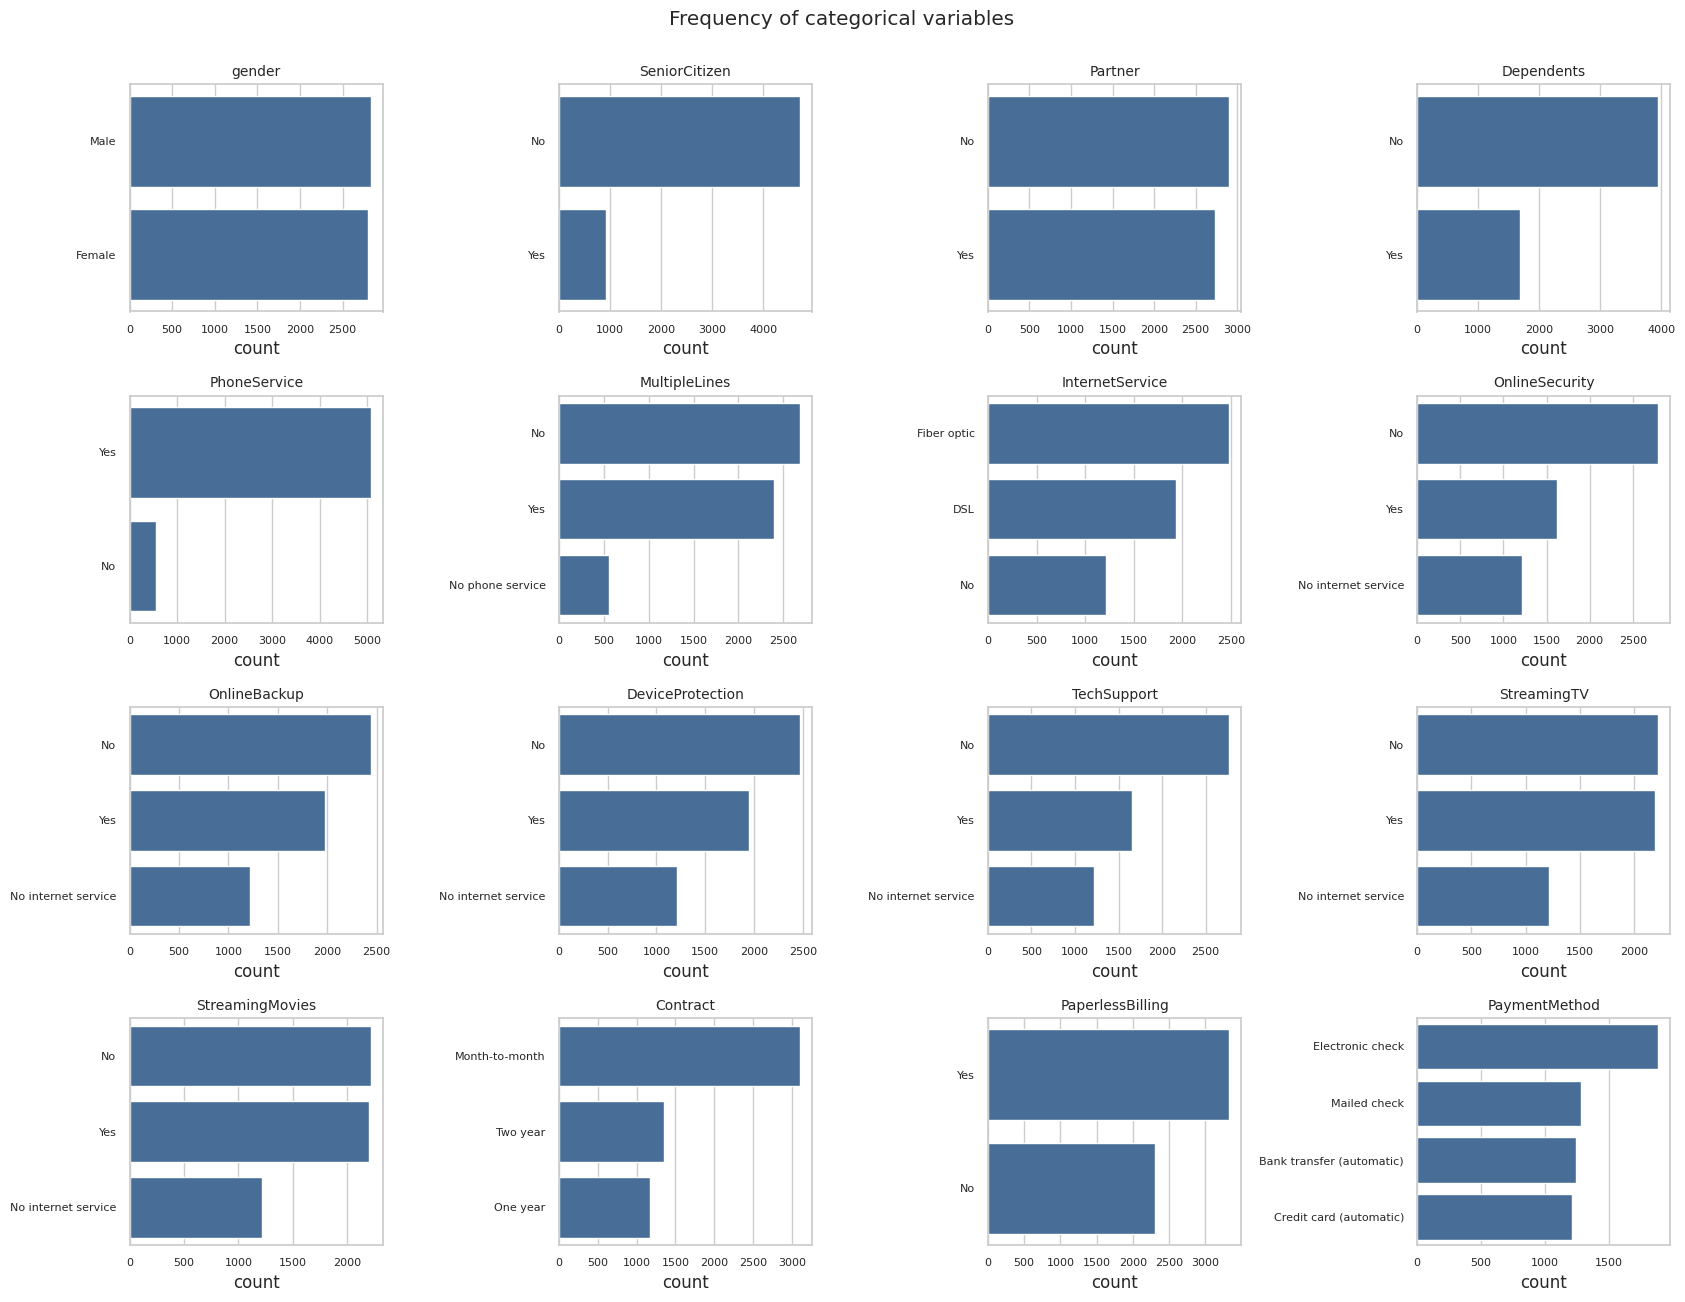

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, col in zip(axes.ravel(), CAT):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=ax, color="#3b6ea5")
    ax.set_title(col, fontsize=10); ax.set_ylabel(""); ax.tick_params(labelsize=8)
plt.suptitle("Frequency of categorical variables", y=1.0); plt.tight_layout(); savefig("eda_categorical_frequencies.png")

## C. Bivariate analysis - how does churn change with each variable?
Bars show the **churn rate** with 95% Wilson confidence intervals (error bars). The red dashed line is the overall churn rate; bars far from it, with intervals that do not cross it, deserve attention.

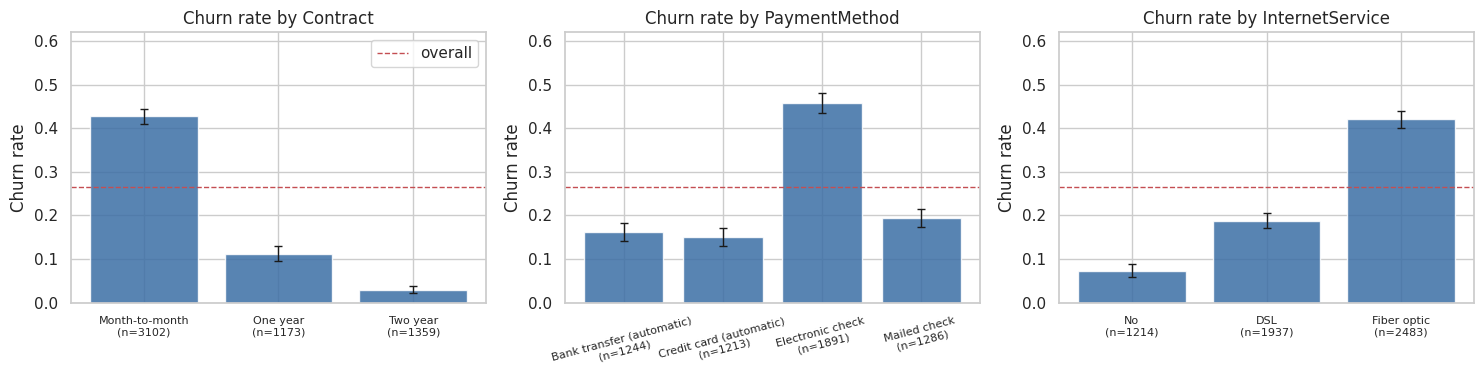

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_rate(df, "Contract", axes[0], ["Month-to-month", "One year", "Two year"])
plot_rate(df, "PaymentMethod", axes[1])
axes[1].tick_params(axis="x", labelrotation=15)
plot_rate(df, "InternetService", axes[2], ["No", "DSL", "Fiber optic"])
axes[0].legend(); plt.tight_layout(); savefig("eda_churn_by_contract_payment_internet.png")

,tenure_band,n,churned,churn_rate,ci_low,ci_high
0,0-6,1170,611,0.522,0.494,0.551
1,7-12,567,211,0.372,0.333,0.413
2,13-24,818,234,0.286,0.256,0.318
3,25-36,669,140,0.209,0.180,0.242
4,37-48,621,121,0.195,0.166,0.228
5,49-60,658,101,0.153,0.128,0.183
6,61-72,1131,77,0.068,0.055,0.084


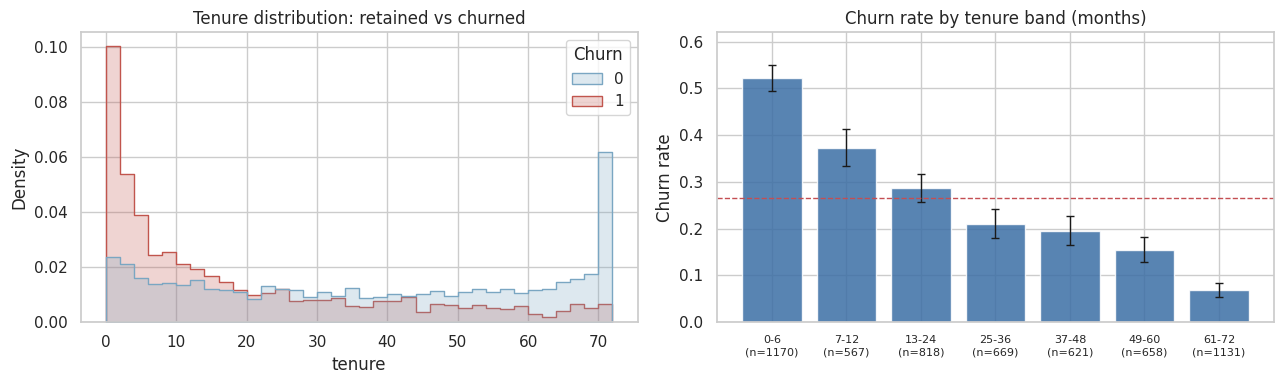

In [7]:
# Tenure: distribution by churn + churn rate per tenure band
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, stat="density", common_norm=False, element="step", ax=axes[0], palette=["#7aa6c2", "#c1554d"])
axes[0].set_title("Tenure distribution: retained vs churned")
bands = pd.cut(df.tenure, [-1, 6, 12, 24, 36, 48, 60, 72], labels=["0-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
tmp = df.assign(tenure_band=bands)
tenure_rates = plot_rate(tmp, "tenure_band", axes[1], title="Churn rate by tenure band (months)")
plt.tight_layout(); savefig("eda_churn_by_tenure.png"); display(tenure_rates.round(3))

,mc_quintile,n,churned,churn_rate,ci_low,ci_high
0,Q1 (lowest),1134,103,0.091,0.075,0.109
1,Q2,1121,276,0.246,0.222,0.272
2,Q3,1126,329,0.292,0.266,0.319
3,Q4,1133,419,0.370,0.342,0.398
4,Q5 (highest),1120,368,0.329,0.302,0.357


      tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
Churn                                                         
0       37.6   38.0           61.3   64.4       2564.7  1686.2
1       18.4   10.0           74.9   80.0       1564.6   740.3


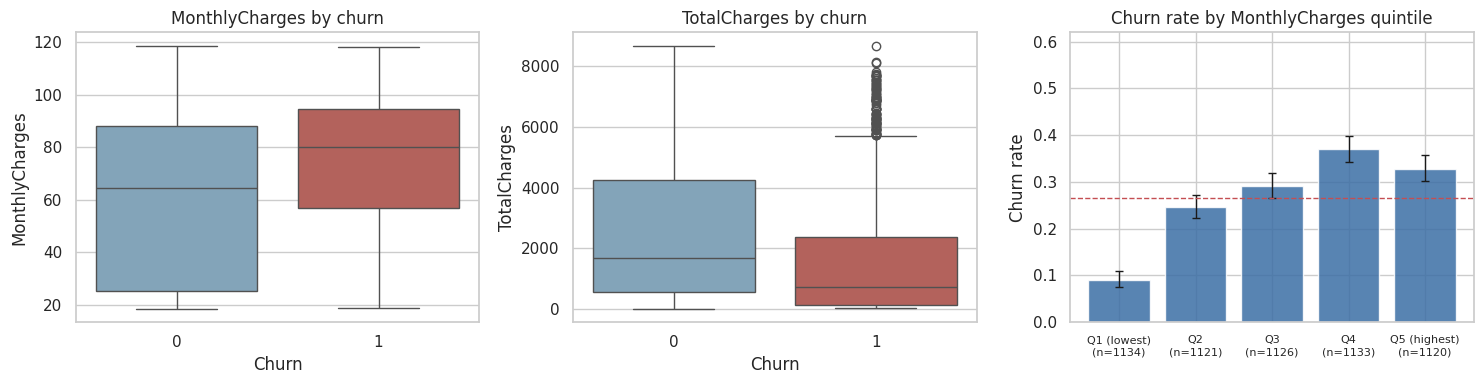

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[0], palette=["#7aa6c2", "#c1554d"]); axes[0].set_title("MonthlyCharges by churn")
sns.boxplot(data=df, x="Churn", y="TotalCharges", ax=axes[1], palette=["#7aa6c2", "#c1554d"]); axes[1].set_title("TotalCharges by churn")
q = pd.qcut(df.MonthlyCharges, 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
mc_rates = plot_rate(df.assign(mc_quintile=q), "mc_quintile", axes[2], title="Churn rate by MonthlyCharges quintile")
plt.tight_layout(); savefig("eda_churn_by_charges.png"); display(mc_rates.round(3))
print(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(1))

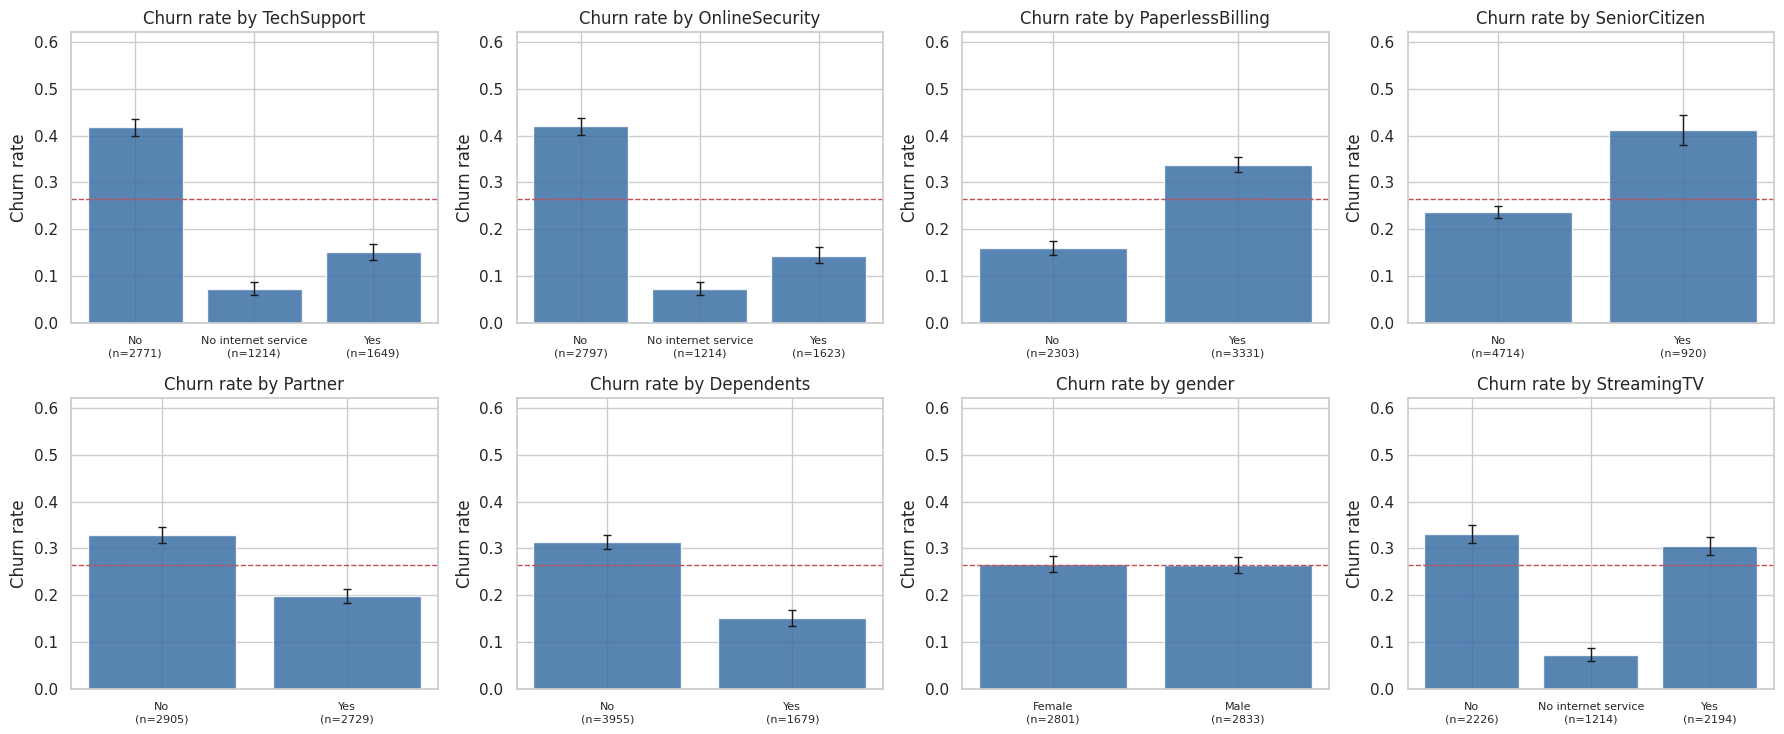

In [9]:
other = ["TechSupport", "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents", "gender", "StreamingTV"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, col in zip(axes.ravel(), other): plot_rate(df, col, ax)
plt.tight_layout(); savefig("eda_churn_by_other_features.png")

## D. Statistical analysis
### D1. Categorical features vs churn: chi-square test + Cramer's V
* **Chi-square test of independence:** asks "if churn were unrelated to this feature, how surprising is the observed table?" *Assumptions:* independent observations; expected cell counts mostly >= 5 (we report the minimum).
* **Cramer's V** (0 = no association, 1 = perfect) is the **effect size** - p-values shrink with sample size, effect sizes do not.
* We test ~16 features, so some "significant" results appear by chance. We apply the **Benjamini-Hochberg** false-discovery-rate correction.

,feature,chi2,dof,p_value,cramers_v,min_expected_count,p_adj_BH
0,Contract,952.3,2,1.62e-207,0.411,311,2.59e-206
1,OnlineSecurity,694.3,2,1.73e-151,0.351,322,1.39e-150
2,TechSupport,670.3,2,2.79e-146,0.345,322,1.49e-145
3,InternetService,600.8,2,3.37e-131,0.327,322,1.35e-130
4,PaymentMethod,545.2,3,7.57e-118,0.311,322,2.42e-117
5,OnlineBackup,488.0,2,1.06e-106,0.294,322,2.82e-106
6,DeviceProtection,441.3,2,1.50e-96,0.280,322,3.43e-96
7,StreamingMovies,302.4,2,2.13e-66,0.232,322,4.26e-66
8,StreamingTV,299.0,2,1.17e-65,0.230,322,2.09e-65
9,PaperlessBilling,219.9,1,9.40e-50,0.198,611,1.50e-49


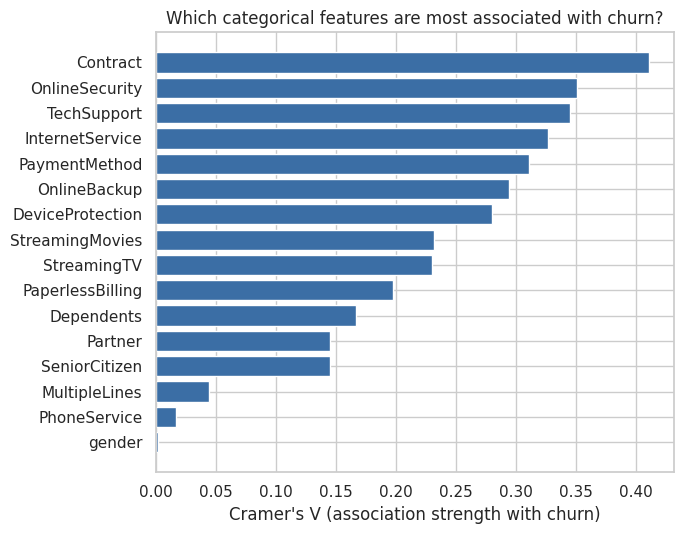

In [10]:
rows = []
for col in CAT:
    ct = pd.crosstab(df[col], df.Churn)
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    n = ct.values.sum(); v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    rows.append({"feature": col, "chi2": chi2, "dof": dof, "p_value": p, "cramers_v": v, "min_expected_count": expected.min()})
cat_tests = pd.DataFrame(rows)
cat_tests["p_adj_BH"] = stats.false_discovery_control(cat_tests["p_value"])
cat_tests = cat_tests.sort_values("cramers_v", ascending=False).reset_index(drop=True)
cat_tests.to_csv(config.REPORTS_DIR / "eda_categorical_tests.csv", index=False)
display(cat_tests.style.format({"chi2": "{:.1f}", "p_value": "{:.2e}", "p_adj_BH": "{:.2e}", "cramers_v": "{:.3f}", "min_expected_count": "{:.0f}"}))

plt.figure(figsize=(7, 5.5))
s = cat_tests.sort_values("cramers_v"); plt.barh(s.feature, s.cramers_v, color="#3b6ea5")
plt.xlabel("Cramer's V (association strength with churn)"); plt.title("Which categorical features are most associated with churn?"); plt.tight_layout(); savefig("eda_cramers_v.png")

### D2. Numeric features vs churn: Mann-Whitney U + Cliff's delta
The numeric variables are skewed (see histograms), so we use the rank-based **Mann-Whitney U test** (compares whole distributions, does not assume normality) instead of a t-test.
**Cliff's delta** is the effect size: the probability that a random churner has a larger value than a random retained customer, minus the reverse (range -1 to 1; |d| of ~0.15/0.33/0.47 are conventionally "small/medium/large").

In [11]:
rows = []
for col in NUM:
    a, b = df.loc[df.Churn == 1, col], df.loc[df.Churn == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature": col, "median_churned": a.median(), "median_retained": b.median(),
                 "mean_churned": a.mean(), "mean_retained": b.mean(), "U": u, "p_value": p, "cliffs_delta": 2 * u / (len(a) * len(b)) - 1})
num_tests = pd.DataFrame(rows); num_tests.to_csv(config.REPORTS_DIR / "eda_numeric_tests.csv", index=False)
display(num_tests.style.format({c: "{:.1f}" for c in ["median_churned", "median_retained", "mean_churned", "mean_retained"]} | {"U": "{:.0f}", "p_value": "{:.1e}", "cliffs_delta": "{:+.3f}"}))

,feature,median_churned,median_retained,mean_churned,mean_retained,U,p_value,cliffs_delta
0,tenure,10.0,38.0,18.4,37.6,1638556,1.1e-160,-0.470
1,MonthlyCharges,80.0,64.4,74.9,61.3,3860744,6.3e-46,+0.248
2,TotalCharges,740.3,1686.2,1564.6,2564.7,2193941,1.4e-62,-0.291


In [12]:
# Uncertainty on a headline comparison: month-to-month vs two-year churn rates
g = churn_rate_by(df, "Contract").set_index("Contract")
m, t = g.loc["Month-to-month"], g.loc["Two year"]
diff = m.churn_rate - t.churn_rate
se = np.sqrt(m.churn_rate * (1 - m.churn_rate) / m.n + t.churn_rate * (1 - t.churn_rate) / t.n)
print(f"Month-to-month {m.churn_rate:.1%} vs Two-year {t.churn_rate:.1%}: difference = {diff:.1%} (95% CI {diff-1.96*se:.1%} to {diff+1.96*se:.1%})")

Month-to-month 42.7% vs Two-year 2.9%: difference = 39.9% (95% CI 37.9% to 41.8%)


### D3. Relationships between numeric features and the danger of confounding
`tenure`, `MonthlyCharges` and `TotalCharges` move together (TotalCharges ~ tenure x MonthlyCharges).
More importantly, features are **confounded**: customers on month-to-month contracts are also mostly newer customers. So a raw churn gap by contract could partly be a *tenure* effect. We can check by looking at one variable *within* levels of another.

tenure band (share of contract type),0-12,13-24,25-48,49-72
Contract,,,,
Month-to-month,0.51,0.19,0.21,0.09
One year,0.08,0.14,0.35,0.43
Two year,0.04,0.05,0.17,0.74


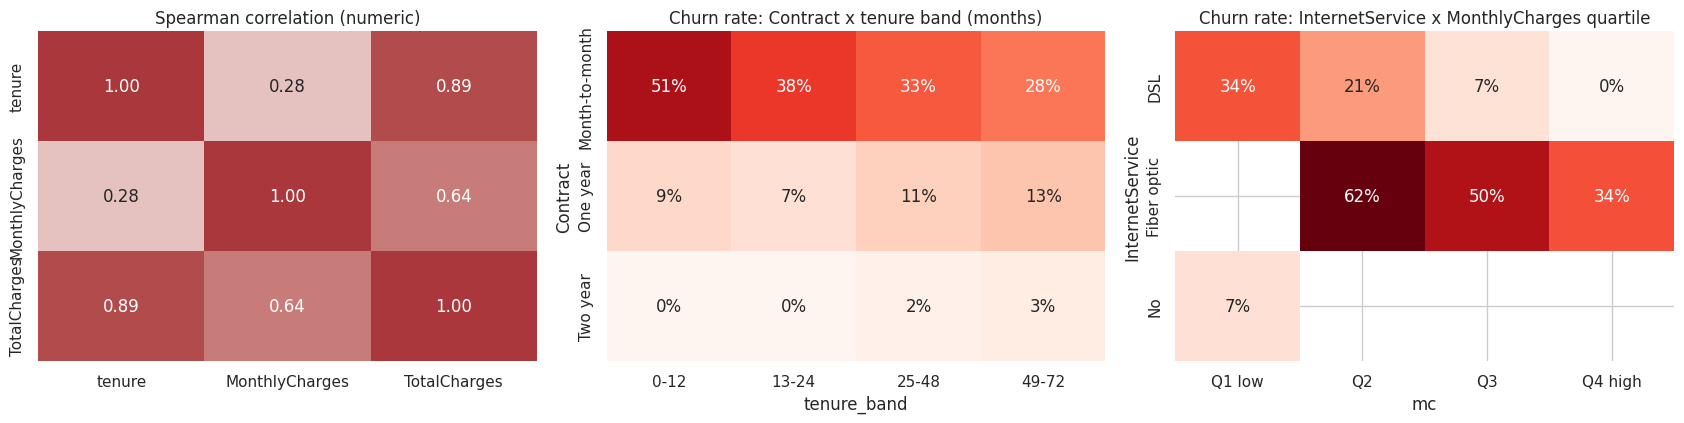

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
sns.heatmap(df[NUM].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0], cbar=False); axes[0].set_title("Spearman correlation (numeric)")

tb = pd.cut(df.tenure, [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
piv1 = df.assign(tenure_band=tb).pivot_table(index="Contract", columns="tenure_band", values="Churn", aggfunc="mean", observed=True)
sns.heatmap(piv1, annot=True, fmt=".0%", cmap="Reds", ax=axes[1], vmin=0, vmax=0.6, cbar=False); axes[1].set_title("Churn rate: Contract x tenure band (months)")

mq = pd.qcut(df.MonthlyCharges, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
piv2 = df.assign(mc=mq).pivot_table(index="InternetService", columns="mc", values="Churn", aggfunc="mean", observed=True)
sns.heatmap(piv2, annot=True, fmt=".0%", cmap="Reds", ax=axes[2], vmin=0, vmax=0.6, cbar=False); axes[2].set_title("Churn rate: InternetService x MonthlyCharges quartile")
plt.tight_layout(); savefig("eda_confounding_checks.png")
display(pd.crosstab(df.Contract, tb, normalize="index").round(2).rename_axis(columns="tenure band (share of contract type)"))

## E. Business interpretation (what the data shows -> why it might matter -> limits -> what evidence is missing)

**Finding 1 - Contract type is the strongest single separator.**
*Shows:* churn is 42.7% for month-to-month (n=3,102), 11.1% for one-year and 2.9% for two-year contracts; the month-to-month vs two-year gap is 39.9 percentage points (95% CI 37.9 to 41.8). Cramer's V = 0.41, the largest of any feature.
*Why it may matter:* month-to-month customers have no commitment barrier, so they are the natural focus of retention effort, and offers that move customers to longer terms could be worth testing.
*Limits:* **selection effect** - customers who choose a 2-year contract are probably already loyal; the contract may be a *symptom* of loyalty, not its cause. The heatmap shows the gap persists *within* tenure bands (e.g. 0-12 months: 51% vs 9% vs 0%), so it is not just a tenure artefact, but unobserved loyalty could still explain it.
*Evidence needed:* an experiment (randomised contract-upgrade offers) - observational data cannot say that *moving* someone to a longer contract reduces their churn.

**Finding 2 - Newer customers churn far more; risk falls steadily with tenure.**
*Shows:* churn is 52% in months 0-6, 37% in 7-12, then falls to 6.8% beyond 5 years. Median tenure is 10 months for churners vs 38 for retained customers (Cliff's delta = -0.47, the largest numeric effect). `TotalCharges` shows a similar (-0.29) effect mostly because it is tenure x price.
*Why it may matter:* the first year is the critical window - onboarding and early-life experience may deserve the most attention.
*Limits:* **survivorship** - long-tenure customers are the ones who *haven't* left, so tenure partly measures "has survived this long". Also, this snapshot records churners' tenure at the time they left (see notebook 01 on leakage-by-snapshot).
*Evidence needed:* cohort/survival analysis with sign-up dates (e.g. Kaplan-Meier curves by acquisition channel).

**Finding 3 - Fiber-optic customers churn much more than DSL, and the raw "higher charges -> more churn" pattern is confounded.**
*Shows:* churn is 42.1% on fiber vs 18.7% on DSL and 7.2% with no internet. Churners pay more per month (median $79.95 vs $64.40; delta = +0.25), **but** within each internet-service type higher charges go with *lower* churn (fiber: 62% -> 50% -> 34% across increasing charge quartiles; DSL: 34% -> 21% -> 7% -> 0%, though the top DSL quartile has only 39 customers). The overall positive association arises because the fiber group (high prices, high churn) is a large share of high-bill customers - a Simpson's-paradox-style mix effect.
*Why it may matter:* "customers who pay more leave more" is the wrong takeaway; the data points instead to the *fiber service/segment* (and possibly add-on bundles - customers with more services pay more *and* churn less). It would be a mistake to respond by cutting prices across the board.
*Limits:* we do not observe service quality, outages, competitor offers or price changes in fiber areas - any of which could drive this.
*Evidence needed:* network-quality, complaint and competitor-pricing data by region; price-change history.

**Finding 4 - Electronic-check payers, customers without support/security add-ons, seniors, paperless-billing customers and those without partners/dependents churn more.**
*Shows:* electronic check 45.7% vs 14.9-19.3% for other payment methods; no TechSupport 41.8% vs 15.2% with it (OnlineSecurity: 41.9% vs 14.4%); SeniorCitizen 41.1% vs 23.7%; paperless billing 33.8% vs 16.0%; no partner 32.8% vs 19.9%; no dependents 31.4% vs 15.2%. All survive the false-discovery correction; effect sizes (Cramer's V) range from 0.14 to 0.35.
*Why it may matter:* services like TechSupport/OnlineSecurity are plausible "stickiness" levers; payment method may be a marker of customer segment or billing friction.
*Limits:* these features are correlated with each other (e.g. add-ons only exist for internet customers) so each one's *separate* contribution is unclear; the comparison "Yes vs No add-on" is among internet customers only. The "No internet service" group is a distinct, low-churn segment (7.2%), which is why we do not read "no add-on" as "bad".
*Evidence needed:* a multivariable model (next notebooks) to estimate each feature's *conditional* association, and experiments for any proposed intervention.

**Finding 5 - Gender and phone service carry essentially no signal.**
*Shows:* female 26.6% vs male 26.4% (chi-square p = 0.89, V = 0.002); PhoneService is not significant after correction (adjusted p = 0.21); MultipleLines is statistically significant (adjusted p = 0.005) but negligible in size (V = 0.04).
*Why it may matter:* "significant" is not "important" - with 5,600 rows tiny effects can reach p < 0.05. Not using `gender` would likely cost nothing in accuracy and avoids fairness concerns.

### Cautions that apply to everything above
* These are **associations in one snapshot of a sample dataset**, not causal effects.
* Multiple comparisons: 19 tests were run; we corrected the categorical ones (BH) but the numeric ones were few and large.
* Statistical tests assume independent customers; households or shared accounts could violate this.

## What to remember / interview questions
* *"Why report confidence intervals and effect sizes, not just p-values?"* - Large samples make trivial effects significant; effect sizes show importance and intervals show precision.
* *"Why Mann-Whitney instead of a t-test?"* - Skewed variables; rank-based test needs no normality assumption (though it compares distributions, not strictly means).
* *"What is Simpson's paradox and where did it show up?"* - An association that reverses/disappears when you condition on a third variable; here charges vs churn within vs across internet-service types.
* *"Does a significant chi-square mean the feature will help the model?"* - No: it is a *univariate* association; the model needs *incremental* information given the other features.